In [2]:
# 🚀 PROJECT : Lung Cancer Prediction - CNN Model

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.layers import Dense, Dropout, Activation, Flatten, Conv2D, MaxPooling2D


In [21]:
# Extract ZIP file
import zipfile
file = zipfile.ZipFile("/content/lung_cancer_dataset.zip")
file.extractall()
file.close()

In [22]:
!pip install split-folders

In [27]:
# Split the dataset into Two files for Training-80% & Testing-20%
import splitfolders
splitfolders.ratio("/content/lung_cancer_dataset",output = "datas",seed = 42,ratio = (0.8, 0.2))

Copying files: 1096 files [00:00, 2117.58 files/s]


In [53]:
# Train & Test split file to Generate Images by applying a Model for Understanding Patterns
training_data = ImageDataGenerator(rescale = 1.0/255)
train_data = training_data.flow_from_directory("/content/datas/train",
                                                target_size = (64,64),
                                                batch_size = 16,
                                                class_mode = "categorical")


test_data = training_data.flow_from_directory("/content/datas/val",
                                             target_size = (64,64),
                                             batch_size = 16,
                                             class_mode = "categorical")

Found 876 images belonging to 3 classes.
Found 220 images belonging to 3 classes.


In [104]:
# Find a shape of Generated image

img = tf.keras.utils.load_img("/content/datas/train/Bengin cases/Bengin case (10).jpg")
np.array(img).shape

(512, 512, 3)

In [94]:
# Train the CNN Model by using Relu & Sigmoid

model = tf.keras.models.Sequential()
model.add(tf.keras.layers.Conv2D(filters=32, padding = "same", kernel_size = 3, activation = "relu", input_shape = [64,64,3]))
model.add(tf.keras.layers.MaxPool2D(pool_size = 2, strides = 2))

model.add(tf.keras.layers.Conv2D(filters = 64, padding = "same", kernel_size = 3, activation = "relu"))
model.add(tf.keras.layers.MaxPool2D(pool_size = 2, strides = 2))

model.add(tf.keras.layers.Flatten())

model.add(tf.keras.layers.Dense(units = 128, activation = "relu"))
model.add(tf.keras.layers.Dropout(0.5))
model.add(tf.keras.layers.Dense(units = 3, activation = "sigmoid"))


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [95]:
model.summary()

Model: "sequential_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_11 (Conv2D)              │ (None, 64, 64, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_11 (MaxPooling2D) │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_12 (MaxPooling2D) │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_5 (Flatten)             │ (None, 16384)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 128)            │     2,097,280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,117,059 (8.08 MB)

 Trainable params: 2,117,059 (8.08 MB)

 Non-trainable params: 0 (0.00 B)

In [96]:
# Compile a model
model.compile(optimizer = "adam", loss = "categorical_crossentropy", metrics = ["accuracy"])


In [97]:
# Fit the Model to get Accuracy and Loss

models = model.fit(train_data, validation_data =test_data, epochs = 5)
print(models)


Epoch 1/5
55/55 ━━━━━━━━━━━━━━━━━━━━ 9s 147ms/step - accuracy: 0.6005 - loss: 0.8801 - val_accuracy: 0.7636 - val_loss: 0.6827
Epoch 2/5
55/55 ━━━━━━━━━━━━━━━━━━━━ 8s 138ms/step - accuracy: 0.8094 - loss: 0.5083 - val_accuracy: 0.8727 - val_loss: 0.3516
Epoch 3/5
55/55 ━━━━━━━━━━━━━━━━━━━━ 10s 130ms/step - accuracy: 0.8881 - loss: 0.3028 - val_accuracy: 0.9318 - val_loss: 0.1967
Epoch 4/5
55/55 ━━━━━━━━━━━━━━━━━━━━ 8s 147ms/step - accuracy: 0.9429 - loss: 0.1670 - val_accuracy: 0.9455 - val_loss: 0.1398
Epoch 5/5
55/55 ━━━━━━━━━━━━━━━━━━━━ 8s 143ms/step - accuracy: 0.9737 - loss: 0.0837 - val_accuracy: 0.9864 - val_loss: 0.0497


In [98]:
# Model Final Accuracy and Loss
loss , accuracy = model.evaluate(test_data)

print("Model Accuracy : ",accuracy)
print("Model Loss     : ",loss)

14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 54ms/step - accuracy: 0.9864 - loss: 0.0497
Model Accuracy :  0.9863636493682861
Model Loss     :  0.04968342185020447


In [99]:
# Give New Image Input to Check the Model Prediction Output

class_name = train_data.class_indices
img = tf.keras.utils.load_img("/content/lung_img.jpg", target_size = (64,64))
img = tf.keras.utils.img_to_array(img)
img = img/255.0
img = np.expand_dims(img, axis = 0)
pred = model.predict(img)
print(pred)
print(class_name)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step
[[0.0069567  0.99831027 0.2553948 ]]
{'Bengin cases': 0, 'Malignant cases': 1, 'Normal cases': 2}


In [106]:
# Final Prediction of Breast Cancer Applying By CNN Model

pred_index = np.argmax(pred)
class_list = list(class_name.keys())
pre_name = class_list[pred_index]
acc_score = (pred[0][pred_index])

print("Prediction Index :",pred_index)
print("Stage of Cancer  :",pre_name)
print("Disease Accuracy :",acc_score)

if pred_index == 0 :
  print("\nResult : Bengining Stage , abnormal/non-cancerous tumor")
elif pred_index == 1 :
  print("\nResult : Cancer Detected !")
else:
  print("\nResult : Not cancer ")


Prediction Index : 1
Stage of Cancer  : Malignant cases
Disease Accuracy : 0.99831027

Result : Cancer Detected !


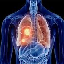

In [107]:
# New Image Shown

imag = tf.keras.utils.load_img("/content/lung_img.jpg", target_size = (64,64))
imag

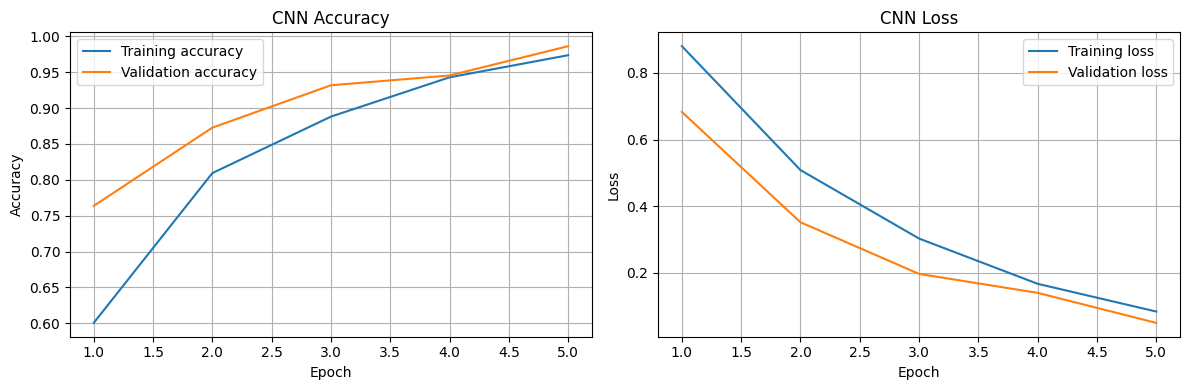

In [103]:
# Plot a Model Accuracy & Loss in a Graph

import matplotlib.pyplot as plt

history = models
acc = history.history["accuracy"]
val_acc = history.history["val_accuracy"]
loss = history.history["loss"]
val_loss = history.history["val_loss"]
epochs = range(1, len(acc) + 1)

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(epochs, acc, label="Training accuracy")
plt.plot(epochs, val_acc, label="Validation accuracy")
plt.title("CNN Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(epochs, loss, label="Training loss")
plt.plot(epochs, val_loss, label="Validation loss")
plt.title("CNN Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.savefig("training_graphs.png", dpi=300)
plt.show()